# Libraries

In [1]:
import os
from pathlib import Path
from ultralytics import YOLO
import cv2
from google import genai
from google.genai import types
import time
import pandas as pd
import numpy as np
from tenacity import retry, stop_after_attempt, wait_exponential
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns


def load_local_env():
    env_file = Path.cwd() / '.env'
    if not env_file.is_file():
        return
    for raw_line in env_file.read_text(encoding='utf-8').splitlines():
        line = raw_line.strip()
        if not line or line.startswith('#') or '=' not in line:
            continue
        key, value = line.split('=', 1)
        os.environ.setdefault(key.strip(), value.strip().strip('\"').strip("'"))

load_local_env()

# Class investigation and manipulation 

In [2]:
classes = os.listdir('data')
path = os.path.join(os.getcwd(), 'data')

In [3]:
@retry(stop=stop_after_attempt(5), wait=wait_exponential(multiplier=1, min=2, max=10))
def translate_to_egyptian_arabic(client, franco_text):
    # Direct generation using gemini-3.5-flash-lite to translate Franco to Egyptian Arabic
    prompt = f"Translate the following Egyptian Franco-Arabic (Arabizi) term into standard Egyptian Arabic. Respond with only the Arabic translation, without any explanations or extra characters: '{franco_text}'"
    response = client.models.generate_content(
        model='gemini-3.5-flash-lite',
        contents=prompt
    )
    return response.text.strip()

@retry(stop=stop_after_attempt(5), wait=wait_exponential(multiplier=1, min=2, max=10))
def get_embedding(client, text):
    response = client.models.embed_content(
        model="gemini-embedding-2",
        contents=text
    )
    return response.embeddings[0].values

def translate_and_embed_classes(dataset_path):
    api_key = os.getenv("GEMINI_API_KEY") or os.getenv("gemini_api")
    if not api_key:
        try:
            api_key = userdata.get("gemini_api")
        except Exception:
            pass

    if not api_key:
        raise ValueError(
            "Gemini API key not found. Add gemini_api=<your-key> to .env for local runs, "
            "or add the gemini_api secret and enable notebook access in Google Colab."
        )

    client = genai.Client(api_key=api_key)
    # dataset_path already points to the project's data folder.
    if not os.path.isdir(dataset_path):
        raise FileNotFoundError(f"Dataset folder not found: {dataset_path}")
    classes_list = [
        name for name in os.listdir(dataset_path)
        if os.path.isdir(os.path.join(dataset_path, name))
    ]

    data_records = []
    print(f"Processing {len(classes_list)} classes...")

    # Track request count to handle the 15 RPM limit
    request_count = 0

    for idx, class_name in enumerate(classes_list):
        print(f"[{idx+1}/{len(classes_list)}] Processing: {class_name}")

        # 1. Translate via gemini-3.5-flash-lite
        try:
            arabic_translation = translate_to_egyptian_arabic(client, class_name)
            request_count += 1
        except Exception as e:
            print(f"Warning: Failed to translate '{class_name}': {e}")
            arabic_translation = class_name

        # Check if we need to pause after translation request limit
        if request_count >= 15:
            print("Rate limit threshold reached (15 requests). Pausing for 1 minute and 10 seconds...")
            time.sleep(70)
            request_count = 0

        # 2. Get embeddings
        try:
            embedding_vector = get_embedding(client, arabic_translation)
            request_count += 1
        except Exception as e:
            print(f"Warning: Failed to get embedding for '{arabic_translation}': {e}")
            embedding_vector = None

        data_records.append({
            'franco_class': class_name,
            'egyptian_arabic_translation': arabic_translation,
            'embedding': embedding_vector
        })

        # Check if we need to pause after embedding request limit
        if request_count >= 15:
            print("Rate limit threshold reached (15 requests). Pausing for 1 minute and 10 seconds...")
            time.sleep(70)
            request_count = 0

    # 3. Create Pandas DataFrame
    df = pd.DataFrame(data_records)
    return df

# Run the function and display the resulting DataFrame
df_embeddings = translate_and_embed_classes(path)
display(df_embeddings.head())

Processing 56 classes...
[1/56] Processing: 3amel eh
[2/56] Processing: 3ieb
[3/56] Processing: 3rabia
[4/56] Processing: 3waz
[5/56] Processing: akhoia
[6/56] Processing: alam
[7/56] Processing: bhab
[8/56] Processing: bkrh
Rate limit threshold reached (15 requests). Pausing for 1 minute and 10 seconds...
[9/56] Processing: bsor3a
[10/56] Processing: delwaty
[11/56] Processing: docktor
[12/56] Processing: efrdha
[13/56] Processing: ehtrem nfsk
[14/56] Processing: elnhrda
[15/56] Processing: ermy wra dhrk
Rate limit threshold reached (15 requests). Pausing for 1 minute and 10 seconds...
[16/56] Processing: fatan
[17/56] Processing: fe sark
[18/56] Processing: flos
[19/56] Processing: fokk many
[20/56] Processing: gomma
[21/56] Processing: harmy
[22/56] Processing: hba hba
[23/56] Processing: helw awy
Rate limit threshold reached (15 requests). Pausing for 1 minute and 10 seconds...
[24/56] Processing: hta hta
[25/56] Processing: kdab
[26/56] Processing: khaif
[27/56] Processing: khaly 

,franco_class,egyptian_arabic_translation,embedding
0,3amel eh,عامل ايه,"[-0.002640398, -0.028785981, 0.0027917153, -0...."
1,3ieb,عيب,"[0.004164381, -0.0311521, 0.036312643, 0.00864..."
2,3rabia,عربية,"[-0.0040964307, -0.012987302, -0.0032232334, 0..."
3,3waz,عوز,"[-0.01128948, -0.0065981513, 0.010548607, 0.01..."
4,akhoia,اخويا,"[0.014867199, -0.014206814, 0.01765253, 0.0005..."


In [4]:
df_embeddings.to_csv('Data Product/class_translations_and_embeddings.csv', index=False)
print ("Data class embeddings saved to 'Data Product/class_translations_and_embeddings.csv'")

Data class embeddings saved to 'Data Product/class_translations_and_embeddings.csv'


In [5]:
# Filter out entries where embedding is None, just in case
valid_df = df_embeddings.dropna(subset=['embedding']).reset_index(drop=True)

# Convert the column of embedding lists into a NumPy array
embeddings_matrix = np.array(valid_df['embedding'].tolist())

# Create a new DataFrame with each element of the vector as its own feature column
embedding_features_df = pd.DataFrame(
    embeddings_matrix,
    columns=[f'emb_feature_{i}' for i in range(embeddings_matrix.shape[1])]
)

# Concatenate the original metadata (franco_class, egyptian_arabic_translation) with the features
adjusted_df = pd.concat([valid_df[['franco_class', 'egyptian_arabic_translation']], embedding_features_df], axis=1)

# Display the adjusted DataFrame
display(adjusted_df.head())
print(f"Adjusted DataFrame shape: {adjusted_df.shape}")

,franco_class,egyptian_arabic_translation,emb_feature_0,emb_feature_1,emb_feature_2,emb_feature_3,emb_feature_4,emb_feature_5,emb_feature_6,emb_feature_7,...,emb_feature_3062,emb_feature_3063,emb_feature_3064,emb_feature_3065,emb_feature_3066,emb_feature_3067,emb_feature_3068,emb_feature_3069,emb_feature_3070,emb_feature_3071
0,3amel eh,عامل ايه,-0.002640,-0.028786,0.002792,-0.008793,-0.005984,0.018946,0.004752,0.011534,...,-0.088892,0.000078,-0.058666,0.006492,0.014521,-0.011024,0.003889,-0.001819,-0.007354,-0.004127
1,3ieb,عيب,0.004164,-0.031152,0.036313,0.008643,0.015745,0.004604,0.019410,-0.003851,...,-0.125015,0.002546,-0.061162,-0.019749,-0.004343,-0.004856,0.002436,-0.006995,-0.004717,-0.015851
2,3rabia,عربية,-0.004096,-0.012987,-0.003223,0.017090,0.007768,0.010689,-0.010970,0.000384,...,-0.120649,0.021195,-0.064578,-0.009478,0.001989,-0.004914,0.003119,-0.008673,0.009092,-0.002288
3,3waz,عوز,-0.011289,-0.006598,0.010549,0.011129,0.009801,0.022450,0.028460,0.005024,...,-0.101366,0.011438,-0.063629,0.003177,-0.012437,-0.008456,0.007088,0.008919,0.000099,-0.017481
4,akhoia,اخويا,0.014867,-0.014207,0.017653,0.000514,-0.002725,0.004396,-0.006937,0.005800,...,-0.106081,0.000864,-0.052788,0.006205,0.002180,0.002087,0.012504,-0.004001,0.000669,-0.001245


Adjusted DataFrame shape: (56, 3074)


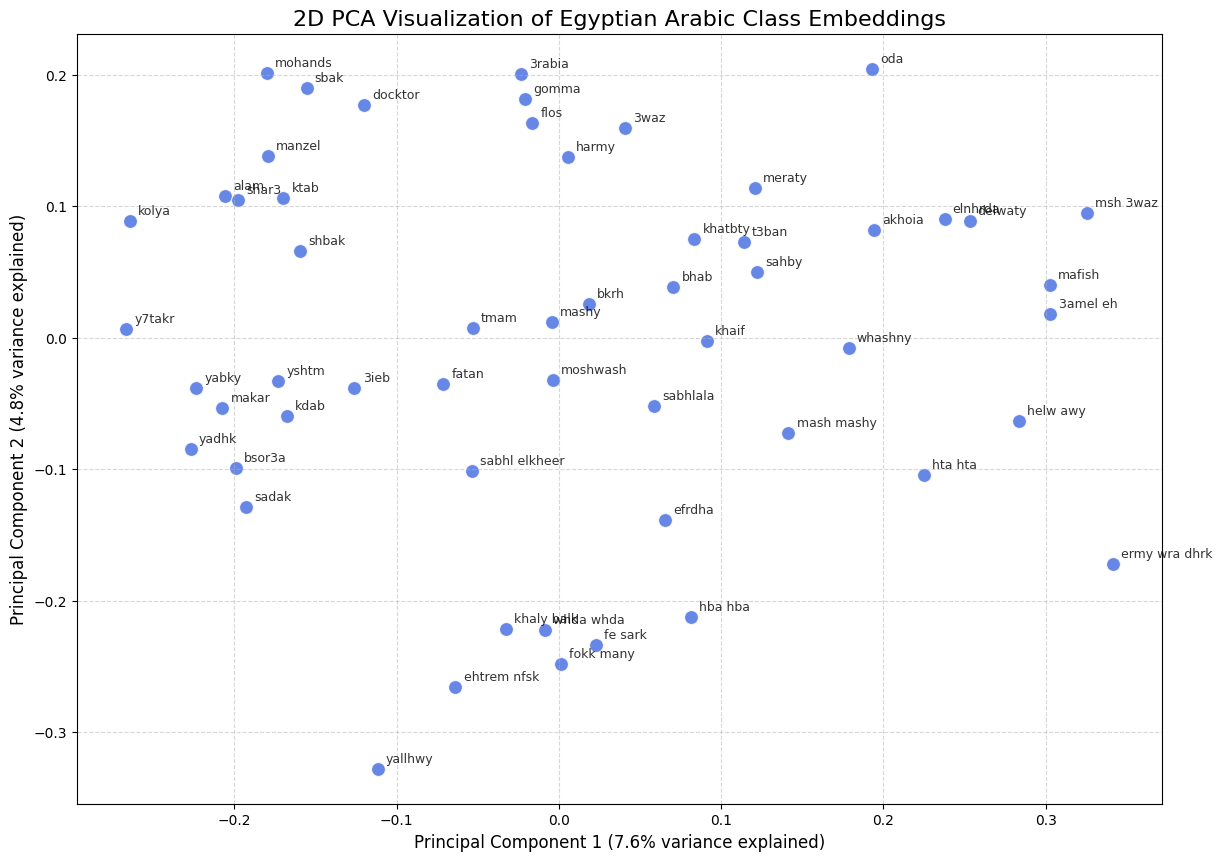

In [6]:
# 1. Extract the feature columns (excluding metadata)
feature_cols = [col for col in adjusted_df.columns if col.startswith('emb_feature_')]
X = adjusted_df[feature_cols].values

# 2. Perform PCA to reduce dimensions to 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# 3. Create a DataFrame for visualization
df_pca = pd.DataFrame(X_pca, columns=['PCA 1', 'PCA 2'])
df_pca['franco_class'] = adjusted_df['franco_class']
df_pca['egyptian_arabic_translation'] = adjusted_df['egyptian_arabic_translation']

# 4. Plot the 2D Projection without generating warnings
plt.figure(figsize=(14, 10))
sns.scatterplot(
    x='PCA 1',
    y='PCA 2',
    data=df_pca,
    s=100,
    color='royalblue',
    alpha=0.8
)

# Annotate the points with their Egyptian Arabic translations
for i, row in df_pca.iterrows():
    plt.text(
        row['PCA 1'] + 0.005,
        row['PCA 2'] + 0.005,
        row['franco_class'],
        fontsize=9,
        alpha=0.8,
        family='sans-serif'
    )

plt.title('2D PCA Visualization of Egyptian Arabic Class Embeddings', fontsize=16)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance explained)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance explained)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Collect coordinates 

In [7]:
# ------------------------------------------------------------------------------
# Extract 17 Pose Keypoint Coordinates from all dataset videos using YOLOv8-pose
# ------------------------------------------------------------------------------

# 17 COCO Keypoints tracked by YOLO Pose
KEYPOINT_NAMES = [
    'nose',
    'left_eye', 'right_eye',
    'left_ear', 'right_ear',
    'left_shoulder', 'right_shoulder',
    'left_elbow', 'right_elbow',
    'left_wrist', 'right_wrist',
    'left_hip', 'right_hip',
    'left_knee', 'right_knee',
    'left_ankle', 'right_ankle'
]

def extract_coordinates_from_videos(
    dataset_path="data",
    model_name="yolov8n-pose.pt",
    device=None,
    max_videos=None,
    save_csv=True,
    csv_filename="Data Product/video_keypoint_coordinates.csv",
    save_parquet=True,
    parquet_filename="Data Product/video_keypoint_coordinates.parquet"
):
    """
    Extracts frame-by-frame pose keypoint coordinates from all videos in dataset_path
    and returns a structured pandas DataFrame.
    """
    if device is None:
        import torch
        device = "cuda" if torch.cuda.is_available() else "cpu"
    
    print(f"Loading YOLO Pose model '{model_name}' on device '{device}'...")
    model = YOLO(model_name)
    
    # 1. Discover all videos grouped by class folder
    video_entries = []
    if not os.path.isdir(dataset_path):
        raise FileNotFoundError(f"Dataset path not found: {dataset_path}")
        
    for class_name in sorted(os.listdir(dataset_path)):
        class_folder = os.path.join(dataset_path, class_name)
        if os.path.isdir(class_folder):
            for file_name in sorted(os.listdir(class_folder)):
                if file_name.lower().endswith(('.mp4', '.avi', '.mov', '.mkv')):
                    full_path = os.path.join(class_folder, file_name)
                    video_entries.append((class_name, file_name, full_path))
                    
    total_found = len(video_entries)
    print(f"Found {total_found} videos across {len(set(v[0] for v in video_entries))} classes.")
    
    if max_videos is not None:
        video_entries = video_entries[:max_videos]
        print(f"Processing a subset of {len(video_entries)} videos (max_videos={max_videos}).")

    from tqdm.auto import tqdm
    records = []
    corrupt_videos = []

    # 2. Iterate through each video
    for class_name, file_name, full_path in tqdm(video_entries, desc="Processing videos"):
        cap = cv2.VideoCapture(full_path)
        opened = cap.isOpened()
        first_frame_ok = False
        if opened:
            first_frame_ok, _ = cap.read()
        fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) or 1
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) or 1
        cap.release()

        if not opened or not first_frame_ok:
            corrupt_videos.append(full_path)
            print(f"Warning: {full_path} is unreadable or corrupt. Skipping.")
            continue

        # Run YOLO Pose streaming inference
        try:
            results = model.predict(
                source=full_path,
                stream=True,
                verbose=False,
                device=device
            )
            
            frame_idx = 0
            for r in results:
                # Default arrays if no person detected in frame
                kpts_xy = np.full((17, 2), np.nan, dtype=np.float32)
                kpts_conf = np.zeros(17, dtype=np.float32)
                
                # Check for keypoint detections
                if r.keypoints is not None and len(r.keypoints.data) > 0:
                    # Pick primary signer detection and enforce the expected 17-keypoint shape
                    keypoints = r.keypoints.data.cpu().numpy()[0]
                    if keypoints.shape == (17, 3):
                        kpts_xy = keypoints[:, :2]
                        kpts_conf = keypoints[:, 2]
                
                # Metadata for this frame
                row = {
                    'video_name': file_name,
                    'class_name': class_name,
                    'frame_idx': frame_idx,
                    'timestamp_sec': round(frame_idx / fps, 3),
                    'frame_width': width,
                    'frame_height': height
                }
                
                # Add (x, y, x_norm, y_norm, conf) for each of the 17 keypoints
                for i, name in enumerate(KEYPOINT_NAMES):
                    x_val = kpts_xy[i, 0]
                    y_val = kpts_xy[i, 1]
                    conf_val = kpts_conf[i]
                    
                    is_valid = not np.isnan(x_val)
                    row[f'{name}_x'] = round(float(x_val), 2) if is_valid else np.nan
                    row[f'{name}_y'] = round(float(y_val), 2) if is_valid else np.nan
                    row[f'{name}_x_norm'] = round(float(x_val / width), 4) if is_valid else np.nan
                    row[f'{name}_y_norm'] = round(float(y_val / height), 4) if is_valid else np.nan
                    row[f'{name}_conf'] = round(float(conf_val), 4)

                records.append(row)
                frame_idx += 1
                
        except Exception as e:
            print(f"Error processing video {file_name}: {e}")

    # 3. Create DataFrame
    df_coordinates = pd.DataFrame(records)
    if corrupt_videos:
        print(f"\nSkipped {len(corrupt_videos)} unreadable/corrupt video(s):")
        for corrupt_path in corrupt_videos:
            print(f"  - {corrupt_path}")

    print(f"Extraction complete! Total frames extracted: {len(df_coordinates):,}")
    print(f"DataFrame dimensions: {df_coordinates.shape} (rows x columns)")
    
    # 4. Save results to Data Product folder
    os.makedirs("Data Product", exist_ok=True)
    if save_csv and not df_coordinates.empty:
        df_coordinates.to_csv(csv_filename, index=False)
        print(f"Coordinates saved to CSV: '{csv_filename}'")
    if save_parquet and not df_coordinates.empty:
        df_coordinates.to_parquet(parquet_filename, index=False)
        print(f"Coordinates saved to Parquet (faster & compressed): '{parquet_filename}'")
        
    return df_coordinates

# Run extraction across all videos (or specify max_videos=5 for a quick test run)
df_coords = extract_coordinates_from_videos(
    dataset_path="data",
    model_name="yolov8n-pose.pt"
)

# Display sample of the resulting coordinates DataFrame
display(df_coords.head())


Loading YOLO Pose model 'yolov8n-pose.pt' on device 'cuda'...
Found 477 videos across 56 classes.


Processing videos:   0%|          | 0/477 [00:00<?, ?it/s]


Skipped 1 unreadable/corrupt video(s):
  - data\khatbty\khatbty_8602.mp4
Extraction complete! Total frames extracted: 35,618
DataFrame dimensions: (35618, 91) (rows x columns)
Coordinates saved to CSV: 'Data Product/video_keypoint_coordinates.csv'
Coordinates saved to Parquet (faster & compressed): 'Data Product/video_keypoint_coordinates.parquet'


,video_name,class_name,frame_idx,timestamp_sec,frame_width,frame_height,nose_x,nose_y,nose_x_norm,nose_y_norm,...,left_ankle_x,left_ankle_y,left_ankle_x_norm,left_ankle_y_norm,left_ankle_conf,right_ankle_x,right_ankle_y,right_ankle_x_norm,right_ankle_y_norm,right_ankle_conf
0,3amel eh_5006.mp4,3amel eh,0,0.000,640,480,269.95,145.89,0.4218,0.3039,...,380.72,480.0,0.5949,1.0,0.0014,153.18,453.80,0.2393,0.9454,0.0014
1,3amel eh_5006.mp4,3amel eh,1,0.033,640,480,269.33,145.54,0.4208,0.3032,...,391.10,480.0,0.6111,1.0,0.0014,155.86,459.42,0.2435,0.9571,0.0014
2,3amel eh_5006.mp4,3amel eh,2,0.067,640,480,269.69,145.23,0.4214,0.3026,...,399.74,480.0,0.6246,1.0,0.0014,161.69,460.36,0.2526,0.9591,0.0014
3,3amel eh_5006.mp4,3amel eh,3,0.100,640,480,270.27,144.38,0.4223,0.3008,...,426.41,480.0,0.6663,1.0,0.0019,172.00,466.94,0.2687,0.9728,0.0019
4,3amel eh_5006.mp4,3amel eh,4,0.133,640,480,267.72,144.38,0.4183,0.3008,...,464.17,480.0,0.7253,1.0,0.0187,330.45,463.28,0.5163,0.9652,0.0129


# Coordinate Summary & Inspection
Summary of extracted keypoints, frame counts per video, and validation.

In [8]:
# Summary metrics
print(f"Total extracted rows (frames): {len(df_coords):,}")
print(f"Total unique videos: {df_coords['video_name'].nunique()}")
print(f"Total classes: {df_coords['class_name'].nunique()}")
print(f"Average frames per video: {df_coords.groupby('video_name')['frame_idx'].count().mean():.1f}")

# Quick check on keypoint detection confidence
conf_cols = [c for c in df_coords.columns if c.endswith('_conf')]
mean_conf = df_coords[conf_cols].mean().sort_values(ascending=False)
print("\nAverage Keypoint Detection Confidence:")
print(mean_conf.head(10))

Total extracted rows (frames): 35,618
Total unique videos: 476
Total classes: 56
Average frames per video: 74.8

Average Keypoint Detection Confidence:
left_shoulder_conf     0.987417
nose_conf              0.984617
right_shoulder_conf    0.983461
right_eye_conf         0.974110
left_eye_conf          0.959261
left_elbow_conf        0.954347
right_elbow_conf       0.934969
right_wrist_conf       0.913598
left_wrist_conf        0.906135
left_hip_conf          0.892792
dtype: float64


In [9]:
print ("\nExtraction and saving of pose keypoint coordinates completed successfully.")


Extraction and saving of pose keypoint coordinates completed successfully.
